# Atari III: renormalising generative models from pixels

This notebook walks the **Atari III** demonstration of **renormalising generative models (RGMs)** for discrete active inference: a simplified Pong-like game is generated from a multi-stream discrete model; a hierarchy is learned from pixel-level (and companion) outcomes; deep dynamics are shaped toward rewarded goals under costs; the recursive model is used for generative (“fantasy”) play and then for active inference with continued structure learning; finally the deep model is compressed while preserving action-relevant predictive structure.

Notation follows our RGM paper (*Renormalising Generative Models for Active Inference*). Equations are rendered in LaTeX and tied to the **variables created in each cell**.


**Local setup.** From the repository root, install dependencies once with `python -m pip install -r requirements.txt`, then open this notebook from the checkout. The next code cell only locates the repo, puts it on `sys.path`, and imports library modules—it does **not** clone the repository or run `pip install`.

**Runtime.** Later cells—especially the active-inference loop of 32 training and structure merging episodes—are computationally heavy; expect a long run for a full notebook pass.


In [ ]:
from __future__ import annotations

import copy
import os
import sys
import time
from datetime import datetime
from pathlib import Path


def _find_repo_root() -> Path:
    """Locate the RGMs checkout (expects python_src/ and requirements.txt)."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        if (cand / "python_src").is_dir() and (cand / "requirements.txt").is_file():
            return cand
    raise FileNotFoundError(
        "Could not find the RGMs repository root (python_src/ and "
        "requirements.txt). Open this notebook from a local checkout after "
        "installing dependencies with: python -m pip install -r requirements.txt"
    )


REPO = _find_repo_root()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib

matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import numpy as np

from python_src.toolbox.DEM.native_driver_rng import seed_native_driver_rng
from python_src.toolbox.DEM.spm_MDP_pong import spm_MDP_pong
from python_src.toolbox.DEM.spm_MDP_generate import spm_MDP_generate
from python_src.toolbox.DEM.dem_atariiii_plot_gameplay import dem_atariiii_plot_gameplay
from python_src.toolbox.DEM.spm_faster_structure_learning import (
    spm_faster_structure_learning,
)
from python_src.toolbox.DEM.spm_merge_structure_learning import (
    spm_merge_structure_learning,
)
from python_src.toolbox.DEM.spm_RDP_basin import spm_RDP_basin
from python_src.toolbox.DEM.dem_atariiii_plot_attractors_basin import (
    dem_atariiii_plot_attractors_basin,
)
from python_src.toolbox.DEM.spm_RDP_sort import spm_RDP_sort
from python_src.toolbox.DEM.spm_set_goals import spm_set_goals
from python_src.toolbox.DEM.dem_atariiii_plot_attractors_mdp_post_sort import (
    dem_atariiii_plot_attractors_mdp_post_sort,
)
from python_src.toolbox.DEM.spm_set_costs import spm_set_costs
from python_src.toolbox.DEM.spm_mdp2rdp import spm_mdp2rdp
from python_src.toolbox.DEM.spm_MDP_VB_XXX import spm_MDP_VB_XXX
from python_src.toolbox.DEM.dem_atariiii_plot_generative_ai import (
    dem_atariiii_plot_generative_ai,
)
from python_src.toolbox.DEM.dem_atariiii_structure_learning_f import (
    structure_learning_f_column,
)
from python_src.toolbox.DEM.dem_atariiii_plot_active_inference_nr import (
    dem_atariiii_plot_active_inference_nr,
)
from python_src.toolbox.DEM.dem_atariiii_plot_structure_learning import (
    dem_atariiii_plot_structure_learning,
)
from python_src.toolbox.DEM.dem_atariiii_plot_before_compression_rgb import (
    dem_atariiii_plot_before_compression_rgb,
)
from python_src.toolbox.DEM.dem_atariiii_plot_orbits_before import (
    dem_atariiii_plot_orbits_before,
)
from python_src.toolbox.DEM.spm_RDP_MI import spm_RDP_MI
from python_src.toolbox.DEM.dem_atariiii_plot_with_compression_rgb import (
    dem_atariiii_plot_with_compression_rgb,
)
from python_src.toolbox.DEM.dem_atariiii_plot_orbits_after import (
    dem_atariiii_plot_orbits_after,
)
from python_src.toolbox.DEM.dem_atariiii_post12 import count_mdp_parameters

for name in ("baseball.png", "bat.png"):
    asset = REPO / "matlab_src" / "toolbox" / "DEM" / name
    assert asset.is_file(), f"missing DEM asset {asset}"

out_dir = REPO / "visualizations" / "DEM_AtariIII"
out_dir.mkdir(parents=True, exist_ok=True)
print("REPO=", REPO, flush=True)


### Cell 1 — Generative process: a discrete Pong-like game

This cell builds the **generative process**—the true game dynamics—not yet the learned hierarchical agent. The call

`GDP, _, _, _, RGB, _ = spm_MDP_pong(Nr, Nc, Nd, 1, 0)`

with `Nr=12`, `Nc=9`, `Nd=4` constructs a partially observed MDP whose tensors live in **`GDP`**. **`RGB`** stores the colour lookup used later to render categorical pixel outcomes as images.

#### Local discrete generative model

In the paper’s notation, each hidden-state factor $f$ has categorical values $s^f$, and a **path** $u^f=h$ selects a transition slice of $B^f$:

$$
p(s_{\tau+1}=i\mid s_\tau=j,\,u_\tau=h,\,B)=B_{ijh}.
$$

Likelihood tensors $A$ map hidden causes to categorical outcomes. In code, these are the lists **`GDP["A"]`** and **`GDP["B"]`** (Dirichlet-normalised transitions), with initial-state / path priors in **`GDP["D"]`**, **`GDP["E"]`**, controllable-path layout in **`GDP["U"]`**, and modality indices in **`GDP["id"]`**.

#### What the Pong process implements

- **Grid.** The leading sensory stream is an `Nr×Nc` array of **pixel** modalities (`Ng = Nr*Nc`). Each pixel has a small categorical alphabet (ball occupancy, bat-related patterns on the bottom row, empty, …).
- **Ball factor.** One latent factor encodes ball location and motion direction on the grid. Transitions bounce when the ball hits a vertical or horizontal boundary (direction components reverse). The corresponding slice of **`GDP["B"][0]`** is that ball dynamics; pixel likelihoods in **`GDP["A"]`** light up the ball’s current cell.
- **Paddle / control factor.** A second factor is the paddle’s **column** on the bottom row, with three controllable paths (move left / stay / move right) encoded in **`GDP["B"][1]`**. Controllability is marked in **`GDP["U"]`** (the paddle factor is the controllable one under random play). Bottom-row pixel likelihoods depend jointly on ball and paddle so that bat–ball geometry is observable.
- **Reward, constraint, and control streams.** Trailing modalities are appended alongside the pixels:
  - **Reward** (index in **`GDP["id"]`**): hit configurations—ball on the bottom row aligned with the paddle.
  - **Constraint / cost** (index in **`GDP["id"]`**): miss configurations—ball on the bottom row **not** aligned with the paddle.
  - **Control** (index in **`GDP["id"]`**): reports paddle column as an outcome (action telemetry).

These separate streams matter later: structure learning and compression can keep deep states that remain informative about reward, cost, and action—not only about pixels.

#### Preferences scale `C`

`C = 32` is the **log preference strength** used later when goals and costs are imposed on the reward and constraint streams (attract hits, avoid misses). It is not applied inside `spm_MDP_pong` itself; it is carried forward as a scalar for subsequent cells.

#### Initial conditions

`Nd` limits how broadly initial-state priors in **`GDP["D"]`** are spread (randomised starts for generation). Together, **`GDP`** is the process model we will sample from next; **`RGB`** is only for visualisation.

In [2]:
seed = seed_native_driver_rng()
print("native RNG seed=", seed, flush=True)

Nr = 12
Nc = 9
Sc = 9
Nd = 4
C = 32

GDP, _hid, _cid, _con, RGB, _nP = spm_MDP_pong(Nr, Nc, Nd, 1, 0)

native RNG seed= 2


### Cell 2 — Random play: a structure-learning corpus

We now sample a long trajectory from the generative process. Setting **`GDP["T"] = 10000`** and **`GDP["tau"] = 1`**, the call

`PDP = spm_MDP_generate(GDP)`

draws outcomes under the process priors and (for the controllable paddle factor) random paths. The result **`PDP`** is the play corpus used for structure learning.

#### Outcomes as evidence

In the paper, categorical evidence entering learning/inference is written $O$ (distinct from the predictive $\hat o$). In this notebook:

- **`PDP["O"]`** — per-modality, per-time probabilistic (or categorical) outcome cells; this is the $O$ time series the hierarchy will be built from.
- **`PDP["o"]`** — dense outcome-index summary across modalities/time; used to locate hits and misses.
- **`PDP["id"]`** — modality indices inherited from the process (reward, constraint, control, …).

#### Stream layout `S`

The array **`S`** tells later fast structure learning how to treat each stream spatially:

- Row 0: pixel stream on an `Nr×Nc` grid (`S[0,:] = [Nr, Nc, 1]`).
- Rows 1–3: scalar companion streams (reward, constraint, policy/control)—each `1×1×1` in this demo.

So $Y^{(1)}$ for renormalisation will be assembled from these streams inside **`PDP["O"]`**, with geometry specified by **`S`**.

#### Hit and miss times

The helpers `spm_get_hits` / `spm_get_miss` scan **`PDP["o"]`** using the reward and constraint indices in **`GDP["id"]`**, returning 1-based times where those trailing outcomes exceed the null level. They are not scoring “skill” yet; they mark episode boundaries for selective assimilation in later cells.

In [3]:
S = np.ones((4, 3), dtype=np.float64)
S[0, :] = [float(Nr), float(Nc), 1.0]


def spm_get_hits(o, id_):
    """MATLAB: find(o(id.reward,:) > 1) — 1-based time indices."""
    ridx = int(np.asarray(id_["reward"], dtype=np.int64).ravel()[0]) - 1
    return (np.flatnonzero(np.asarray(o[ridx, :], dtype=np.float64) > 1.0) + 1).astype(np.int64)


def spm_get_miss(o, id_):
    """MATLAB: find(o(id.contraint,:) > 1)."""
    cidx = int(np.asarray(id_["contraint"], dtype=np.int64).ravel()[0]) - 1
    return (np.flatnonzero(np.asarray(o[cidx, :], dtype=np.float64) > 1.0) + 1).astype(np.int64)


GDP = copy.deepcopy(GDP)
GDP["tau"] = 1.0
GDP["T"] = 10000.0
PDP = spm_MDP_generate(GDP)
assert isinstance(PDP, dict), type(PDP)
assert "O" in PDP and "o" in PDP and "id" in PDP

### Cell 3 — Gameplay figure

This cell visualises one frame of the generated corpus before any structure learning.

`dem_atariiii_plot_gameplay(PDP, {"RGB": RGB}, t=128, …)` reads column $t=128$ of **`PDP["O"]`** and renders:

1. **Top panel — `frame_rgb`.** Categorical pixel outcomes at that time are mapped through **`RGB`** via `spm_O2rgb`, producing an `H×W×3` image of the Pong-like scene (ball and bat geometry on the `Nr×Nc` grid).
2. **Lower panel — `control`.** The control-stream outcome at the same time (paddle column telemetry from **`PDP["O"]`** at the control modality index in **`PDP["id"]`**), shown as a small image strip.

Together, the figure checks that the generative process in **`GDP`**, the sampled trajectory in **`PDP`**, and the renderer **`RGB`** are aligned before we build a hierarchical model from **`PDP["O"]`**.

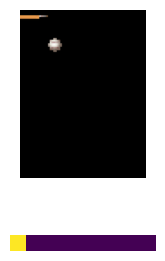

In [4]:
png_path = out_dir / "AtariIII_colab1_dem_gameplay.png"
plot_ctx = {"RGB": RGB}
frame_rgb, control, written = dem_atariiii_plot_gameplay(PDP, plot_ctx, t=128, save_png=True, png_path=png_path)
plt.show()
assert written is not None and Path(written).is_file(), written

### Cell 4 — Fast structure learning on Atari play

This cell builds a **hierarchical RGM** from the random-play corpus, then selectively assimilates **rewarded** episode windows into that hierarchy.

#### Renormalisation of the Pong sequence

Fast structure learning implements the constructive renormalisation step of the paper. At level $n$, observations over sites $i$, times $t$, and channels $c$ are written $Y^{(n)}_{i,t,c}$. One RG step learns a level model and emits coarser data for the next level:

$$
\mathcal{R}_n:\quad
Y^{(n)}
\longmapsto
\big(M^{(n)},\,Y^{(n+1)}\big).
$$

**In this notebook:**

- $Y^{(1)}$ begins as the multi-stream outcomes in **`PDP["O"]`**: leading **pixel** modalities on the `Nr×Nc` grid, plus trailing reward, constraint, and control streams (layout **`S`** from Cell 2).
- The first 1000 frames are sliced into **`O_1000`** (`PDP["O"]` columns $1{:}1000$).
- **`MDP = spm_faster_structure_learning(O_1000, S, Sc)`** applies a stack of $\mathcal{R}_n$ steps. The list **`MDP`** holds the learned levels $M^{(n)}$ (each with Dirichlet likelihood/transition cells **`a`**, **`b`**, and parent/stream ids). Coarser $Y^{(n+1)}$ are the upward state/path summaries built inside that routine.
- **`Sc`** (Cell 1) is the spatial scale $dx_n$ used when grouping sites on the pixel grid.

#### Grouping sites by temporal dependence

Sites that share temporal structure are candidates to share a hidden cause. Pairwise dependence is summarised by a mutual-information matrix $I$ ($I_{ij}$ large when sites $i$ and $j$ co-vary over time). Group membership $z$ maximises shared structure under a size cap $dx_n$:

$$
\max_z\; z^\top I z,
\qquad
z_i\in\{0,1\},
\qquad
\sum_i z_i \le dx_n.
$$

The fast routine uses a spectral relaxation (principal eigenvector of $I$, then a hard group from the largest entries). **Here**, sites are the pixel (and companion-stream) locations organised by **`S`**, with group-size scale **`Sc`**.

#### Patterns become hidden states; $A$ and $B$ accumulate counts

Within a group $G_k^{(n)}$, recurring local outcome patterns are labelled as latent states: $s^{(n)}_{k,t}=\ell$ means the configuration at time $t$ belongs to pattern class $\ell$. Soft evidence is binned by pattern similarity; upward summaries are typically hard one-hots $\hat s^{(n)}_{k,t}=e_\ell$.

State–outcome and state–transition–path counts update Dirichlet parameters

$$
\tilde a = a + N_A,
\qquad
\tilde b = b + N_B,
$$

so posterior means $\mu(\tilde a)$, $\mu(\tilde b)$ define local likelihoods $A$ and path-conditioned transitions $B_{ijh}$. **In code**, those countable tensors live in **`MDP[n]["a"]`** and **`MDP[n]["b"]`** at each level $n$.

#### Upward summaries and downward empirical priors

Each retained group passes state and path summaries to the next level at selected times $t_\tau$ (stride $dt_n$):

$$
Y^{(n+1)}_{k,\tau,1}=\hat s^{(n)}_{k,t_\tau},
\qquad
Y^{(n+1)}_{k,\tau,2}=\hat u^{(n)}_{k,t_\tau}.
$$

Read downward, higher-level likelihoods over those summaries become empirical priors $D$ and $E$ on child initial states and paths. In **`MDP`**, those vertical links are the hierarchical id / mapping structure among levels—the same parent–child interface later used for recursive generation and active inference.

#### Hierarchy depth and temporal stride

After FSL,

$$
\texttt{Nm}=\lvert\texttt{MDP}\rvert,
\qquad
\texttt{Ne}=\max\big(2^{\texttt{Nm}-1},\,1\big).
$$

**`Ne`** is the phase stride used when assimilating windows so each hierarchical timescale sees aligned segments of play.

#### Forget countable parameters; keep structure

The loops that replace every **`MDP[n]["a"][g]`** and **`MDP[n]["b"][f]`** with empty arrays **reset Dirichlet counts** while leaving the hierarchical wiring (streams, parents, ids) intact. The next merges can therefore accumulate parameters from **selected** episodes rather than from the entire random corpus indiscriminately.

#### Merge rewarded windows into `MDP`

Using hits **`r`** and misses **`c`** from Cell 2’s helpers on **`PDP["o"]`** / **`GDP["id"]`**, each hit time that has a preceding miss defines a window from that miss to the hit (shifted by **`Ne`**). For each phase $s=1,\ldots,\texttt{Ne}$,

`MDP = spm_merge_structure_learning(O_seg, MDP)`

assimilates the corresponding columns of **`PDP["O"]`**. This is Atari’s selective structure update: keep paths of play that end in **reward** and avoid **constraint** outcomes, written into the same hierarchy **`MDP`**.

Prints such as **`Nm`**, **`Ne`**, hit/miss counts, merge-call count, and the deep **`b`** shape report the size of the resulting Atari RGM.

In [5]:
O_1000 = [[row[t] for t in range(1000)] for row in PDP["O"]]

MDP = spm_faster_structure_learning(O_1000, S, Sc)

Nm = len(MDP)
Ne = max(2 ** (Nm - 1), 1)
_EMPTY = np.zeros((0, 0), dtype=np.float64)
for n in range(Nm):
    for g in range(len(MDP[n]["a"])):
        MDP[n]["a"][g] = _EMPTY.copy()
    for f in range(len(MDP[n]["b"])):
        MDP[n]["b"][f] = _EMPTY.copy()

r = spm_get_hits(PDP["o"], GDP["id"])
c = spm_get_miss(PDP["o"], GDP["id"])

n_merged = 0
for i in range(len(r)):
    ri = int(r[i])
    prev = c[c < ri]
    if prev.size == 0:
        continue
    s0 = int(prev[-1])
    t = np.arange(s0 + Ne, ri + Ne + 1, dtype=np.int64)
    if t.size == 0:
        continue
    for s in range(1, Ne + 1):
        cols = (t + int(s)).astype(np.int64)
        O_seg = [ [PDP["O"][g][int(col) - 1] for col in cols.tolist()] for g in range(len(PDP["O"])) ]
        MDP = spm_merge_structure_learning(O_seg, MDP)
        n_merged += 1

### Cell 5 — Basins of attraction toward goals

The hierarchy now exists; this cell **shapes its deepest dynamics** so that latent states support paths to **rewarded** configurations while avoiding **costly** ones—structure learning continued in reference to goal states (basins of attraction).

#### Preferences on trailing streams

Each iteration ends with

`MDP, d, o, h, _ = spm_RDP_basin(MDP, [2, 3], [C, -C])`

Streams **`[2, 3]`** are the **reward** and **constraint** modalities (the trailing streams from Cell 1). Log strengths **`[C, -C]`** with `C=32` attract hits and repel misses when goals/costs are imposed on the deep model. Intended deep states are indexed by **`h`** (and costly ones are excluded from admissible transitions inside the basin routine).

#### What one basin step does

Conceptually, with deep transitions given by the support of the deepest **`B`** (in code: **`MDP[Nm-1]["b"][0]`**):

1. Impose goals/costs on those trailing streams (preferred vs aversive deep outcomes).
2. Mark deep states that lie on constrained paths **to or from** goal states (basin of attraction under the allowed transition graph).
3. **Compress** the hierarchy to retain only those deep states.
4. Return indicators:
   - **`d`** — which deep states have children (outgoing transitions);
   - **`o`** — which have parents (incoming transitions);
   - **`h`** — remaining goal-state indices.

#### Training loop: merge blocks, then basin

For iteration $i=1,\ldots,128$ (or until early stop):

1. Take a length-`NT` (`NT=100`) block of **`PDP["O"]`**, offset by wrapping through the corpus, and merge it into **`MDP`** with the same **`Ne`**-phase pattern as Cell 4 (`spm_merge_structure_learning`).
2. Call **`spm_RDP_basin`** as above.
3. Record geometry of the deepest transition tensor:
   - **`NS`** — number of deep states (columns of deep $B$);
   - **`NU`** — number of deep paths (slices of deep $B$);
   - **`NA`** — count of childless deep states ($\neg d$);
   - **`NO`** — count of orphan deep states ($\neg o$);
   - **`NH`** — number of goal states ($\lvert h\rvert$).

#### Stopping rule

The loop **breaks when `all(d)`** is true: every remaining deep state has a child. In the sense used by this demo, deep dynamics are then fully **transient** (no absorbing deep state left in that indicator)—a deep graph oriented toward goals under costs.

#### Attractors figure

`dem_atariiii_plot_attractors_basin(series, …)` plots the recorded series against iteration index:

- **Deep states** — **`NS`**
- **Deep paths** — **`NU`**
- **Childless states** — **`NA`**, overlaid with goal count **`NH`**
- **Orphan states** — **`NO`**

Read these panels as the deep RGM being repeatedly expanded by new play and then reduced to the basin of attraction of rewarded deep states.

  i=1 NS=872 NU=5 NA=59 NO=79 NH=40
  i=8 NS=1073 NU=5 NA=51 NO=111 NH=40
  i=16 NS=1277 NU=5 NA=43 NO=129 NH=40
  i=24 NS=1467 NU=5 NA=38 NO=157 NH=40
  i=32 NS=1598 NU=5 NA=29 NO=169 NH=40
  i=40 NS=1783 NU=5 NA=28 NO=193 NH=40
  i=48 NS=1910 NU=5 NA=26 NO=213 NH=40
  i=56 NS=2052 NU=5 NA=19 NO=226 NH=40
  i=64 NS=2167 NU=6 NA=17 NO=237 NH=40
  i=72 NS=2272 NU=6 NA=15 NO=262 NH=40
  i=80 NS=2362 NU=6 NA=12 NO=276 NH=40
  i=88 NS=2462 NU=6 NA=11 NO=285 NH=40
  i=96 NS=2540 NU=6 NA=9 NO=293 NH=40
  i=104 NS=2597 NU=6 NA=7 NO=298 NH=40
  i=112 NS=2622 NU=6 NA=6 NO=299 NH=40
  i=120 NS=2641 NU=6 NA=6 NO=298 NH=40
  i=128 NS=2657 NU=6 NA=4 NO=297 NH=40


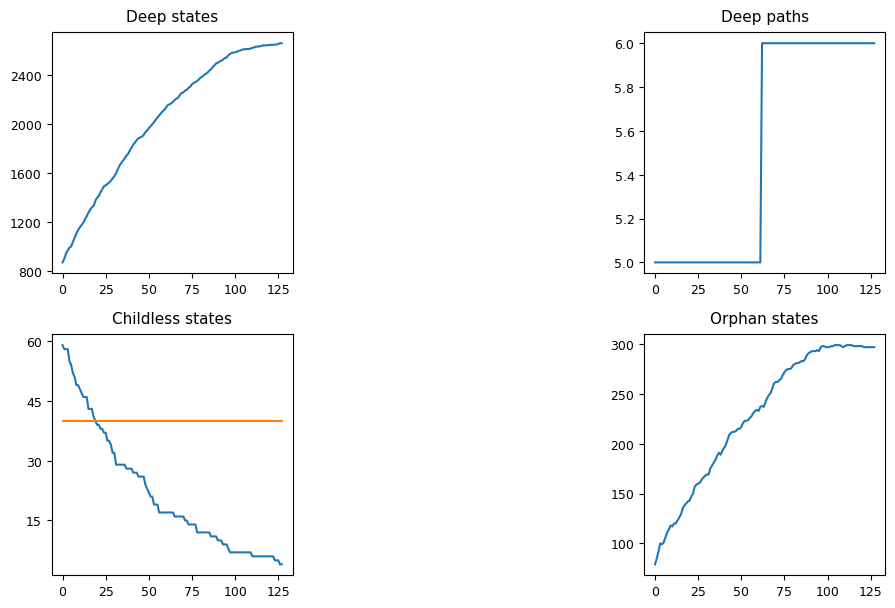

In [6]:
def _b1_matrix(mdp_level):
    """MATLAB MDP{Nm}.b{1} — unwrap one-cell wrappers if present."""
    b = mdp_level["b"][0]
    if isinstance(b, (list, tuple)):
        b = b[0]
    return np.asarray(b, dtype=np.float64)


NT = 100
NS, NU, NA, NO, NH = [], [], [], [], []

for i in range(1, 129):
    offset = int(np.remainder(i, 100 - 1)) * NT
    t = np.arange(0, NT + Ne + 1, dtype=np.int64) + offset
    for s in range(1, Ne + 1):
        cols = (t + int(s)).astype(np.int64)
        O_seg = [
            [PDP["O"][g][int(col) - 1] for col in cols.tolist()]
            for g in range(len(PDP["O"]))
        ]
        MDP = spm_merge_structure_learning(O_seg, MDP)
    MDP, d, o, h, _c = spm_RDP_basin(MDP, [2, 3], [float(C), -float(C)])
    b1 = _b1_matrix(MDP[Nm - 1])
    NS.append(int(b1.shape[1]) if b1.ndim >= 2 else 1)
    NU.append(int(b1.shape[2]) if b1.ndim >= 3 else 1)
    NA.append(int(np.sum(~np.asarray(d, dtype=bool).ravel())))
    NO.append(int(np.sum(~np.asarray(o, dtype=bool).ravel())))
    NH.append(int(np.asarray(h, dtype=np.int64).ravel().size))
    if i == 1 or i % 8 == 0:
        print(
            f"  i={i} NS={NS[-1]} NU={NU[-1]} NA={NA[-1]} NO={NO[-1]} NH={NH[-1]}",
            flush=True,
        )
    if np.all(np.asarray(d, dtype=bool).ravel()):
        print(f"  break at i={i} (all deep states transient)", flush=True)
        break

png_path = out_dir / "AtariIII_colab1_dem_attractors_basin.png"
series = {"NS": NS, "NU": NU, "NA": NA, "NO": NO, "NH": NH}
*_ser, written = dem_atariiii_plot_attractors_basin(series, {"RGB": RGB, "GDP": GDP, "Nm": Nm}, save_png=True, png_path=png_path)
plt.show()
assert written is not None and Path(written).is_file(), written

### Cell 6 — Sort deep states and visualise goal-directed geometry

After basin training, this cell **reduces and orders** the deepest latent space, re-imposes goals, and plots the resulting deep transition geometry.

#### Sort / prune the deep model

`MDP, _ = spm_RDP_sort(MDP)` acts on the deepest transition structure. From the deepest factor’s Dirichlet transitions **`MDP[-1]["b"][0]`** (denoted $B$ below), form a flow on the support of transitions (summed over paths, normalised):

$$
B^{\mathrm{flow}}_{ij}
\;\propto\;
\mathbf{1}\!\left[\sum_h B_{ijh}>0\right].
$$

A leading spectral weighting of $B^{\mathrm{flow}}$ supplies a nonequilibrium steady-state (NESS)–style density over deep states. States with vanishingly small density are pruned when removing them preserves a non-absorbing deep graph; the surviving states are **reordered** by that density and the hierarchy is **compressed** accordingly. The returned **`MDP`** is the reduced deep RGM; **`Nm = len(MDP)`** is refreshed after the sort.

#### Re-apply goals

`MDP = spm_set_goals(MDP, [2, 3], [C, -C])` again marks intended vs aversive deep outcomes on the reward and constraint streams. Goal indices are read as **`hid = MDP[Nm-1]["id"]["hid"]`**. The deep transition tensor used for plotting is **`b1`** from **`MDP[Nm-1]["b"][0]`**.

#### Attractors figure (post-sort)

`dem_atariiii_plot_attractors_mdp_post_sort({"b1": b1, "hid": hid}, …)` draws two panels from those objects:

1. **Orbits.** A low-dimensional embedding of trajectories under deep $B$ (via `spm_dir_orbits` on **`b1`**), with goal states **`hid`** highlighted—the geometry of pullback toward rewarded deep states.
2. **Paths to hits.** With binary support $B^{\mathrm{supp}}_{ij}=\mathbf{1}[\sum_h B_{ijh}>0]$, the panel **`I`** shows, over a short horizon, which deep states can reach the goal set **`HID`** (`hid`) by walking the deep graph; red markers locate the goals on the state axis.

Together, the figure is a readout of the **goal-conditioned deep policy graph** after sort—preparation for generative and active use of the RGM.

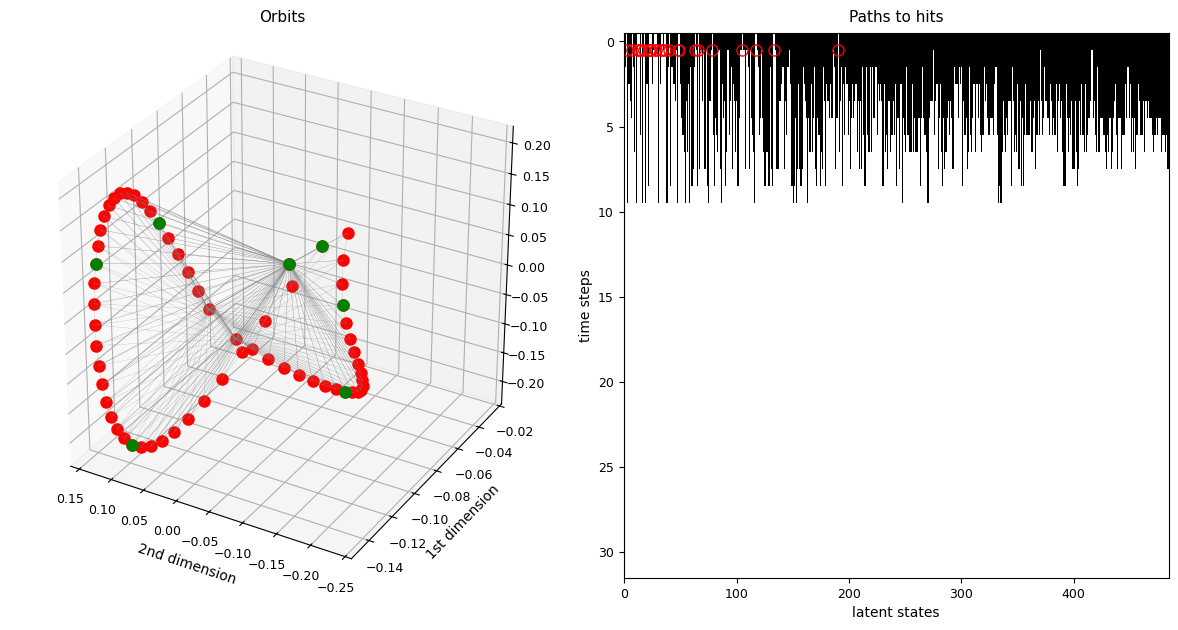

In [7]:
MDP, _j = spm_RDP_sort(MDP)
Nm = len(MDP)
MDP = spm_set_goals(MDP, [2, 3], [float(C), -float(C)])
hid = MDP[Nm - 1]["id"].get("hid", [])
hid = np.asarray(hid, dtype=np.int64).ravel()
b0 = MDP[Nm - 1]["b"][0]
b1 = np.asarray(b0[0] if isinstance(b0, list) else b0, dtype=np.float64)

png_path = out_dir / "AtariIII_colab1_dem_attractors_mdp_post_sort.png"
u, I, HID, written = dem_atariiii_plot_attractors_mdp_post_sort({"b1": b1, "hid": hid}, {"RGB": RGB, "GDP": GDP, "Nm": Nm}, save_png=True, png_path=png_path, eig=None, svd=None, )
plt.show()
assert written is not None and Path(written).is_file(), written

### Cell 7 — Generative (“fantasy”) play under the recursive model

This cell assembles the learned hierarchy into a **recursive generative model** and runs a finite-horizon inversion/generation **without** coupling to the true Pong process. That is **fantasy play**: the agent imagines a trajectory under its own RGM.

#### What “fantasy play” means here

In Cells 1–2, outcomes were produced by the **process** **`GDP`**. Here, beliefs and predicted outcomes come from inverting the **learned** nested model alone. The process tensors (`GDP["A"]`, `GDP["B"]`, …) are **not** installed into the lowest level, so paddle actions do not close a loop through the real game. (Cell 8 will install that process for active inference.)

#### Assembly chain (code ↔ model)

Starting from the sorted hierarchy **`MDP`**:

1. **`RDP = spm_set_goals(deepcopy(MDP), [2, 3], [C, -C])`** — preferred deep outcomes on reward / constraint streams.
2. **`RDP = spm_set_costs(RDP, [2, 3], [C, -C])`** — complementary costs/constraints on those streams.
3. **`RDP = spm_mdp2rdp(RDP)`** — nest level-wise MDPs into a single recursive structure ready for hierarchical inversion.
4. **`RDP["T"] = 64`** — generative horizon.
5. **`PDP = spm_MDP_VB_XXX(RDP)`** — reference variational inversion / generation over that horizon; posterior and predictive quantities live in **`PDP`** (including nested **`PDP["Q"]`**).

#### Overview mathematics distinct to the RGM

A flat MDP has ordinary state priors. An RGM replaces a child’s initial-state prior by a **parent-dependent empirical prior** $D$: when the parent occupies value $\ell$, column $D_{\cdot\ell}$ is the prior over the child’s opening state. Paths have the analogous link $E$. In hierarchical inference, messages run both ways—for a schematic two-level couple,

$$
q(s^{(1)})
=
\sigma\!\big(m_{\downarrow D}+m_{\uparrow A}\big),
\qquad
q(s^{(2)})
=
\sigma\!\big(\log\pi+m_{\uparrow D}\big),
$$

with descending empirical-prior message $m_{\downarrow D}$ from $D$ and ascending evidence $m_{\uparrow D}$ from the child (paper notation; $A$ supplies sensory likelihood messages). **In this cell**, those couplings are wired inside **`RDP`** by `spm_mdp2rdp`; **`spm_MDP_VB_XXX`** recursively contextualises lower episodes with higher states and returns summaries upward into **`PDP`**.

Temporal factors still use path-conditioned transitions $B_{ijh}$. Controllable paths can be biased by expected free energy $G$,

$$
\pi_G(h)
=
\operatorname{norm}_h\!\big(\pi^u_h\,e^{-\alpha G_h}\big),
$$

so imagined play can prefer paths whose predicted consequences have low $G$. That planning prior is part of what the generative call evaluates along the horizon **`RDP["T"]`**.

Fundamentals of local variational message passing (the generic $A$/$B$ message identities behind these updates) are developed in the Supplementary Material: https://doi.org/10.5281/zenodo.20533539.

#### Generative AI figure

`dem_atariiii_plot_generative_ai(PDP, {"RGB": RGB, "GDP": GDP, "Nm": Nm}, …)` renders the fantasy trajectory from **`PDP`**: hierarchical state/outcome predictions organised by depth **`Nm`**, pixel predictions mapped through **`RGB`**, and hit markers from the reward stream of the generated play. It is a visual check that the recursive model can produce coherent Pong-like sequences under goals/costs—before the process is installed for real closed-loop play.

/content/RGMs/python_src/toolbox/DEM/vb_VBX.py:48: RuntimeWarning: divide by zero encountered in log
  return np.fmax(np.log(np.asarray(A, dtype=float)), -32.0)


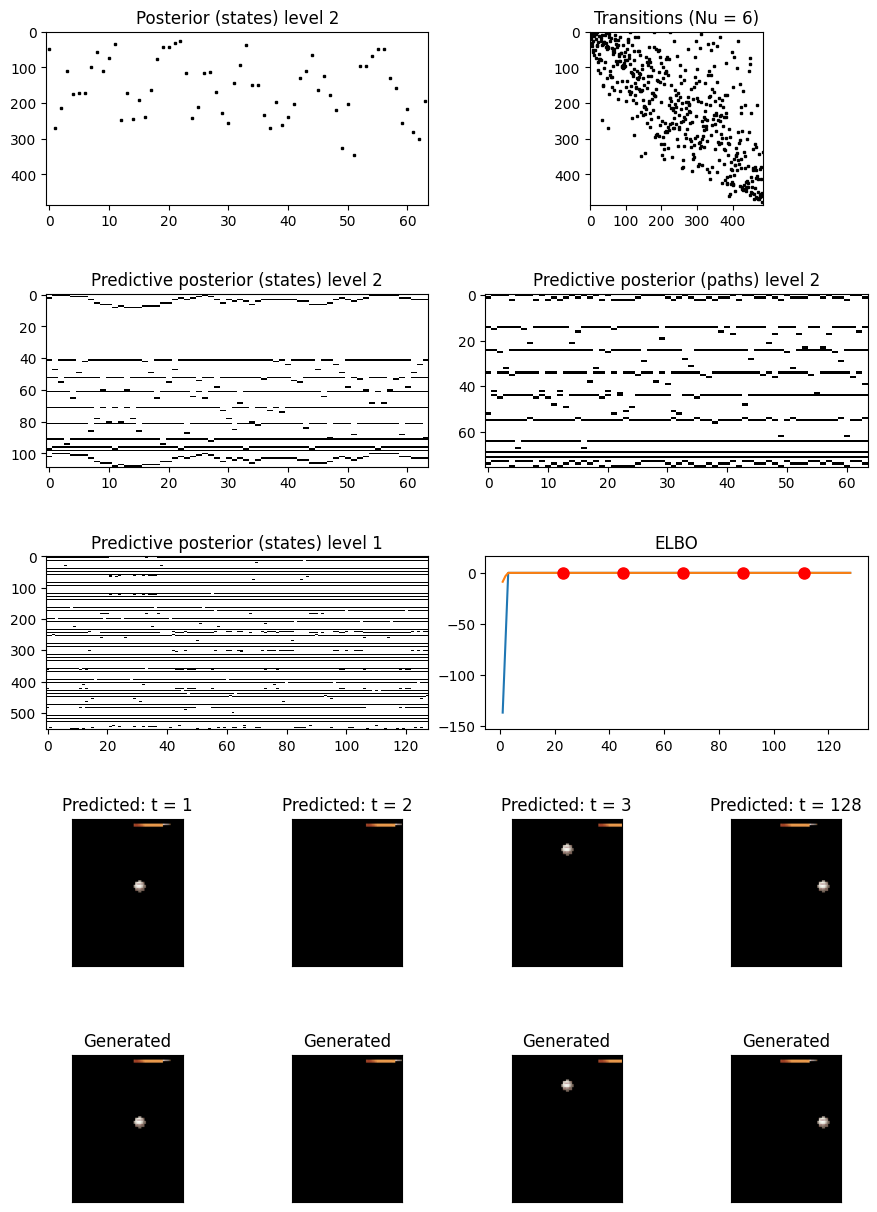

In [8]:
RDP = spm_set_goals(copy.deepcopy(MDP), [2, 3], [float(C), -float(C)])
RDP = spm_set_costs(RDP, [2, 3], [float(C), -float(C)])
RDP = spm_mdp2rdp(RDP)
RDP["T"] = 64.0
PDP = spm_MDP_VB_XXX(RDP)

png_path = out_dir / "AtariIII_colab1_dem_generative_ai.png"
plot_ctx = {"RGB": RGB, "GDP": GDP, "Nm": Nm}
J, K, h_hits, written = dem_atariiii_plot_generative_ai(PDP, plot_ctx, save_png=True, png_path=png_path)
plt.show()
assert written is not None and Path(written).is_file(), written

### Cell 8 — Active inference and continued structure learning

Cell 7 imagined play under the RGM alone. This cell **closes the loop**: the true Pong process is installed at the lowest level, the agent plays $\texttt{NR}=32$ games by active inference, and each game’s self-generated outcomes are merged back into **`MDP`** (with basin reduction)—online structure learning referenced to goals.

#### Install the generative process (explicit action)

The notebook assigns process tensors onto level 0 of **`MDP`**:

- `MDP[0]["GA"] = GDP["A"]`, `MDP[0]["GB"] = GDP["B"]`, `MDP[0]["GU"] = GDP["U"]`, `MDP[0]["GD"] = GDP["D"]`, `MDP[0]["ID"] = GDP["id"]`
- `MDP[0]["chi"] = 512`

These fields equip level 0 with the **process** likelihoods, transitions, controllability, priors, and modality ids from **`GDP`**. During inversion, predicted control outcomes can be realised by acting on the paddle. **`chi`** scales sticky / noisy action (a “shaky hand”): large $\chi$ keeps successive actions persistent rather than perfectly sharp.

#### Planning under expected free energy

Controllable paths are scored by expected free energy. A one-step posterior-predictive form is

$$
G(k)
\approx
\underbrace{\sum_g D_{\mathrm{KL}}\!\big(\hat o^{g,k}_{\tau+1}\,\big\|\,p_{\mathrm{pref}}^g\big)}_{\text{risk}}
+
\underbrace{\sum_g \sum_{s_{\mathrm{pa}(g)}} Q_k(s_{\mathrm{pa}(g)})\,H_{\mathrm{amb}}^g(s_{\mathrm{pa}(g)})}_{\text{ambiguity}}
-
\underbrace{N(k)}_{\text{epistemic value}}.
$$

Path (or joint policy) priors favour low $G$:

$$
q(k)=\operatorname{norm}_k\!\big(\pi_0(k)\,e^{-\alpha G(k)}\big).
$$

In play, preferences $p_{\mathrm{pref}}$ on reward vs constraint streams come from **`spm_set_goals` / `spm_set_costs`** with **`[C,-C]`**; **`spm_MDP_VB_XXX`** evaluates $G$ along the game horizon inside **`RDP`**.

#### Soft priors for continued learning

Each game assembles

`RDP = spm_mdp2rdp(RDP, 0, 1/NS)` with **`NS = 256`**,

so Dirichlet concentration is scaled by $1/\texttt{NS}$. Weaker priors leave room for **parameter updates** from new play (exploration / plasticity), rather than locking the model after Cells 4–6.

Game length in hierarchical time is **`RDP["T"] = floor(NT/Ne)`** with **`NT = 256`** (frames at the finest scale) and **`Ne`** from the hierarchy depth.

#### One game (the loop body)

For $i=1,\ldots,\texttt{NR}$:

1. **Goals / costs** → **`spm_mdp2rdp(..., 1/NS)`** → **`PDP = spm_MDP_VB_XXX(RDP, {})`** — infer, plan, and act for one game; results in **`PDP`**.
2. **Record** a column of metrics via `structure_learning_f_column(PDP, MDP, GDP["id"])` (see **`F`** below). *Note:* this snapshot uses the current **`MDP`** *before* this game’s merge/basin.
3. On the **last** game only, plot active inference (below).
4. **Learn from this play:** take level-1 generative outcomes **`O = PDP["Q"]["O"][0]`** (fallback `"o"`), and for each phase $s=1,\ldots,\texttt{Ne}$ merge segments into **`MDP`** with `spm_merge_structure_learning`.
5. **`MDP, *_ = spm_RDP_basin(MDP, [2, 3], [C, -C])`** — re-prune deep states to the goal basin under costs.

This is the paper’s Atari pattern: play by active inference, then continue structure learning from self-generated multi-stream outcomes.

#### The metric matrix `F`

After all games, **`F = column_stack(F_cols)`** has shape $(6,\texttt{NR})$. Row $r$ of column $i$ is:

| Row | Symbol in plots | Meaning (`structure_learning_f_column`) |
|-----|-----------------|----------------------------------------|
| 0 | Latent states | Deep state count from **`PDP["B"]`** (columns of deep $B$) |
| 1 | Latent paths | Deep path count from **`PDP["B"]`** (slices of deep $B$) |
| 2 | ELBO | $\texttt{PDP["Q"]["F"]} + \sum \texttt{PDP["F"]}$ — variational free-energy / ELBO aggregate for the game |
| 3 | Reward count | Number of hits in **`PDP["Q"]["o"][0]`** (reward stream) |
| 4 | (deep states in `MDP`) | Deep state count from **`MDP[-1]["b"]`** *before* this game’s merge |
| 5 | (deep paths in `MDP`) | Deep path count from **`MDP[-1]["b"]`** *before* this game’s merge |

#### Figures

1. **Active inference** (`dem_atariiii_plot_active_inference_nr` on the final **`PDP`**): hierarchical predictions and rendered play under the installed process, with hit markers—closed-loop intentional play after $\texttt{NR}$ games of learning.
2. **Structure learning** (`dem_atariiii_plot_structure_learning` on **`F`**): traces over games of latent states, latent paths, ELBO, and reward count (and related deep-size rows as plotted)—how behaviour and model geometry co-evolve during continued learning.

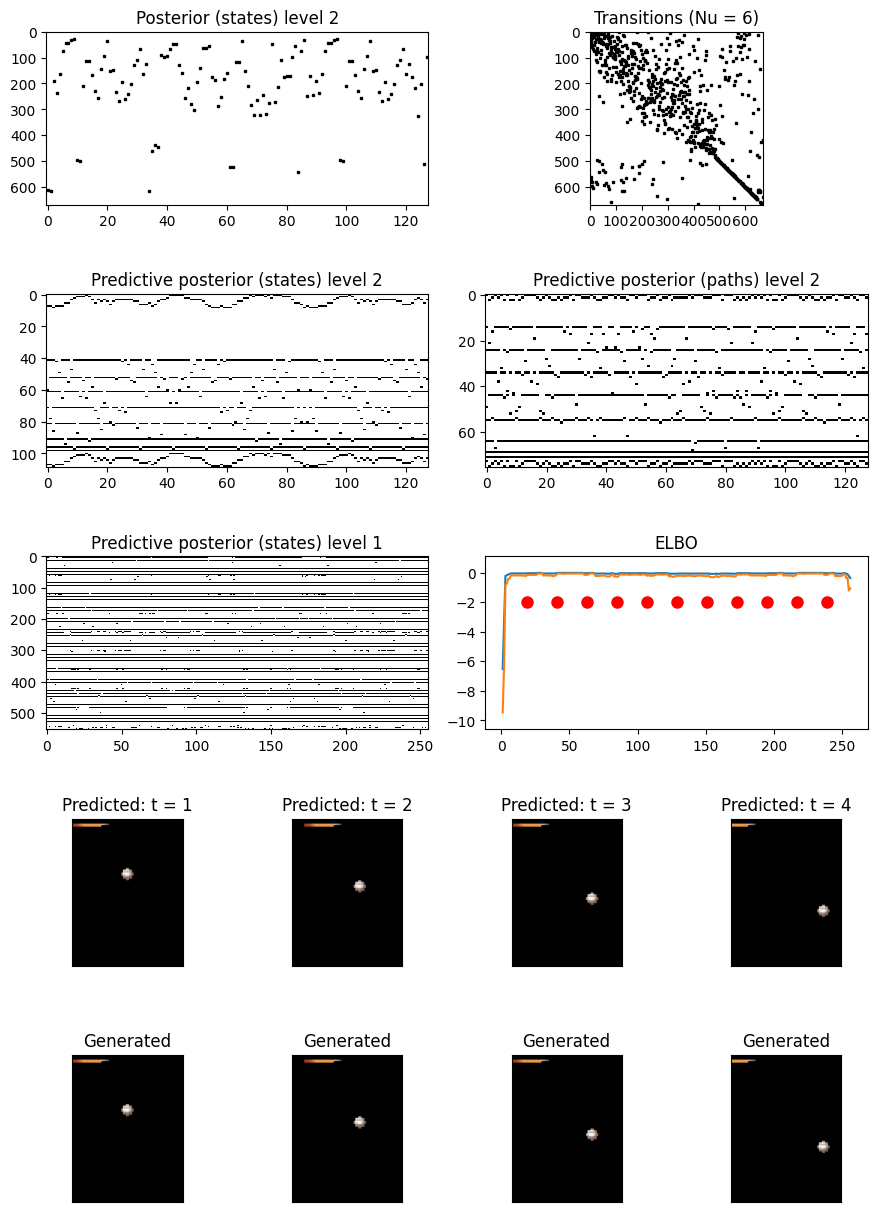

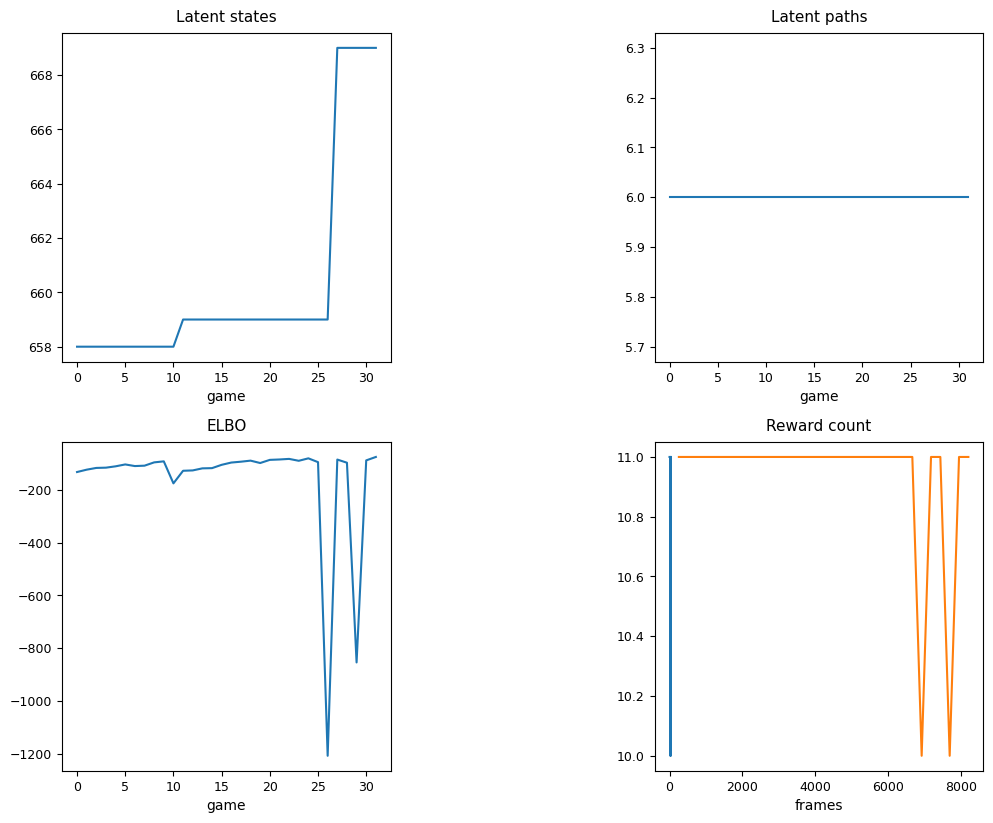

In [10]:
def _q_o_level1_cells(pdp):
    """MATLAB PDP.Q.O{1} as list-of-stream rows for merge."""
    q = pdp["Q"]
    level1 = q.get("O", q.get("o"))[0]
    out = []
    for row in level1:
        r = []
        for col in row:
            arr = np.asarray(col, dtype=np.float64)
            if arr.ndim == 1:
                arr = arr.reshape((-1, 1), order="F")
            elif arr.ndim == 0:
                arr = np.reshape(arr, (1, 1), order="F")
            r.append(arr)
        out.append(r)
    return out


MDP = copy.deepcopy(MDP)
MDP[0]["GA"] = GDP["A"]
MDP[0]["GB"] = GDP["B"]
MDP[0]["GU"] = GDP["U"]
MDP[0]["GD"] = GDP["D"]
MDP[0]["ID"] = GDP["id"]
MDP[0]["chi"] = 512.0

NT = 256
NR = 32
NS = 256
Nm = len(MDP)
F_cols = []
plot_ctx = {"RGB": RGB, "GDP": GDP, "Nm": Nm}

for i in range(1, NR + 1):
    RDP = spm_set_goals(MDP, [2, 3], [float(C), -float(C)])
    RDP = spm_set_costs(RDP, [2, 3], [float(C), -float(C)])
    RDP = spm_mdp2rdp(RDP, 0, 1.0 / float(NS))
    RDP["T"] = float(int(NT / Ne))

    PDP = spm_MDP_VB_XXX(RDP, {})

    F_cols.append(structure_learning_f_column(PDP, MDP, GDP["id"]))

    if i == NR:
        png_ai = out_dir / "AtariIII_colab1_dem_active_inference_nr.png"
        dem_atariiii_plot_active_inference_nr(PDP, plot_ctx, save_png=True, png_path=png_ai)
        plt.show()

    O = _q_o_level1_cells(PDP)
    t = np.arange(0, NT - Ne + 1, dtype=np.int64)
    for s in range(1, Ne + 1):
        cols = (t + int(s)).astype(np.int64)
        O_seg = [[O[g][int(c) - 1] for c in cols.tolist()] for g in range(len(O))]
        MDP = spm_merge_structure_learning(O_seg, MDP)

    MDP, *_ = spm_RDP_basin(MDP, [2, 3], [float(C), -float(C)])


F = np.column_stack(F_cols)
png_sl = out_dir / "AtariIII_colab1_dem_structure_learning.png"
dem_atariiii_plot_structure_learning({"F": F}, plot_ctx, save_png=True, png_path=png_sl, nt=NT)
plt.show()

#vb_mean = float(np.mean(vb_secs)) if vb_secs else float("nan")
#vb_med = float(np.median(vb_secs)) if vb_secs else float("nan")

### Cell 9 — Intentional play before compression

After the $\texttt{NR}$ learning loop, this cell evaluates the **post-learning hierarchy before mutual-information compression**. It is the baseline for the paired Cell 10 figures.

#### Assembly (no MI merge)

From the learned **`MDP`**:

1. **`RDP, _ = spm_RDP_sort(MDP)`** — NESS-style sort/prune of deep states (as in Cell 6).
2. **`spm_set_goals` / `spm_set_costs`** on streams `[2, 3]` with `[C, -C]`.
3. **`RDP = spm_mdp2rdp(RDP, 0, 1/NS)`** — nest with the same soft concentration scale **`NS`** used in Cell 8.
4. **`RDP["T"] = 128`** — longer horizon than fantasy play (Cell 7 used $T=64$).
5. **`PDP = spm_MDP_VB_XXX(RDP, {})`** — active inversion/generation under the **uncompressed** (post-sort) recursive model.

The process install from Cell 8 remains on **`MDP[0]`** (`GA`/`GB`/…), so this is closed-loop-capable play under the rich deep geometry left after continued learning.

#### Figures (before)

1. **`dem_atariiii_plot_before_compression_rgb(PDP, …)`** — hierarchical RGB rendering of intentional play from **`PDP`**, with hit markers (reward stream).
2. **`dem_atariiii_plot_orbits_before(PDP, …)`** — deep **orbits** under **`PDP`**’s deep $B$, plus **paths to hits (before)** over a short horizon from the deep transition support toward goal states.

Hold these panels in mind: Cell 10 repeats the same kinds of plots after an MI-preserving deep reduction.

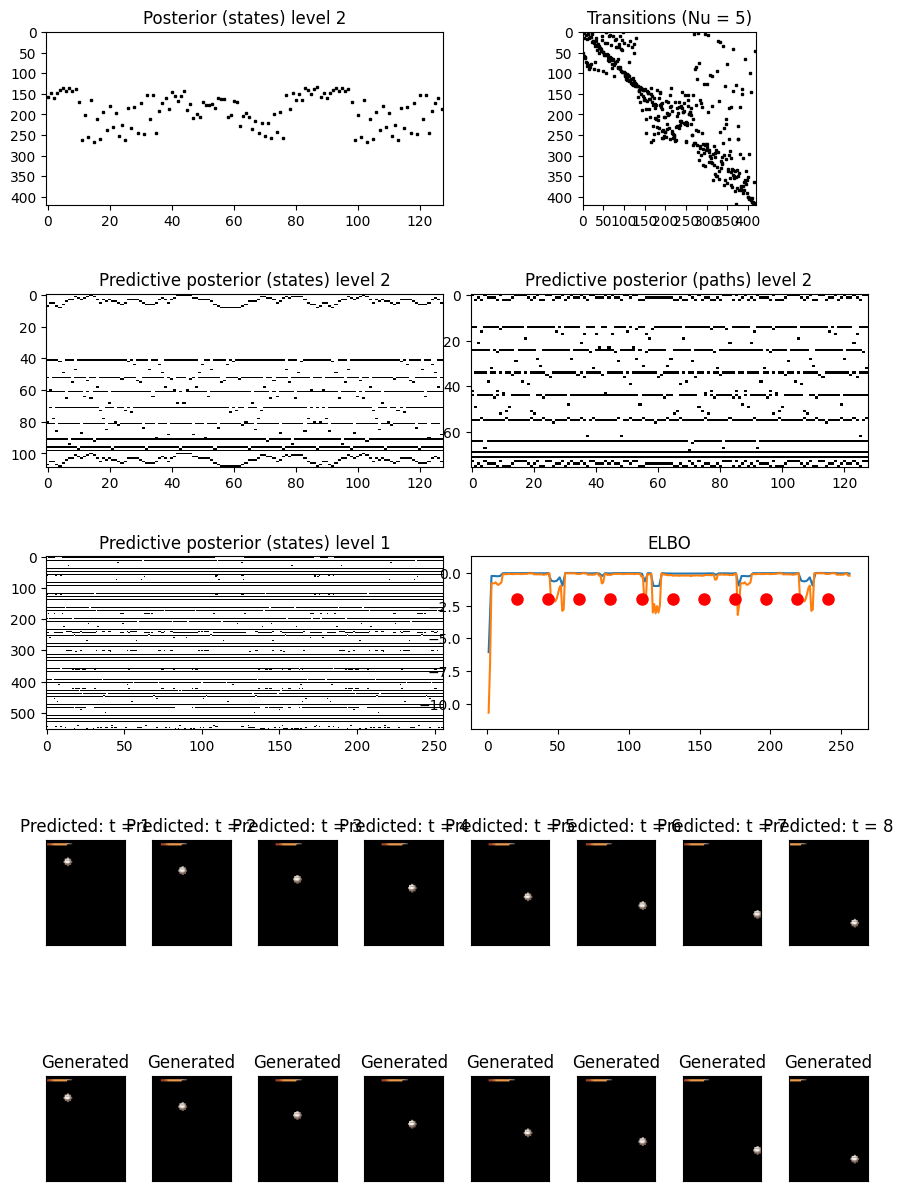

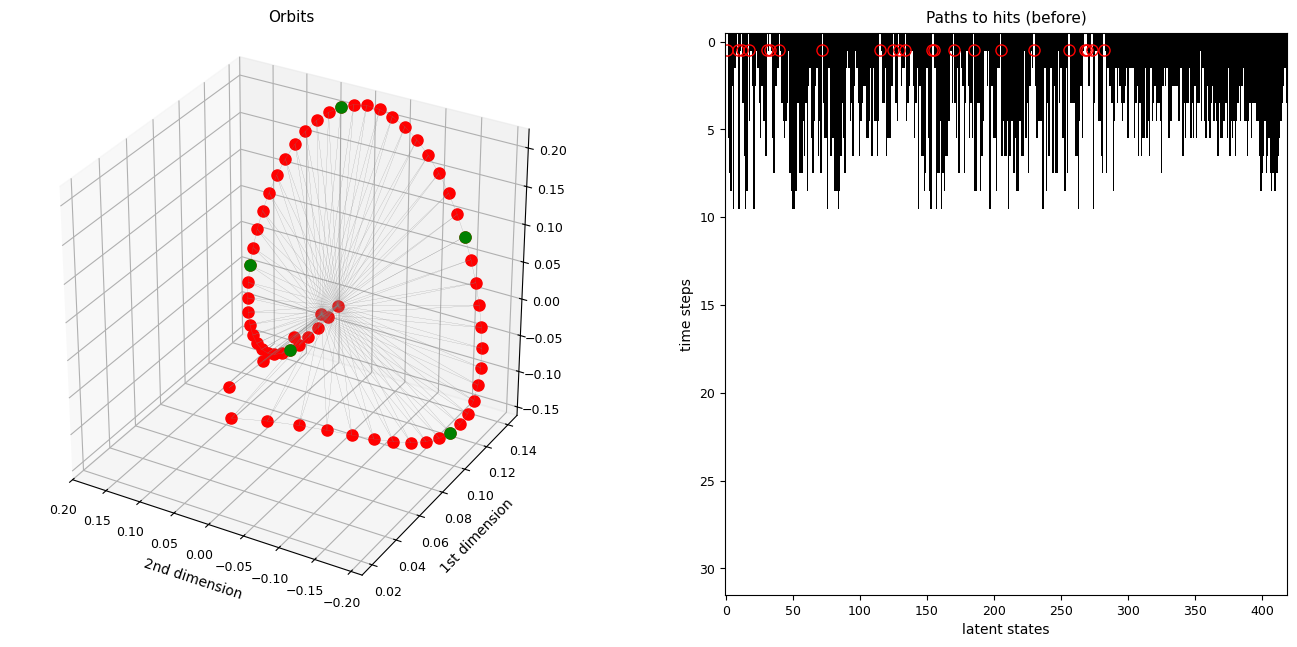

In [11]:
Nm = len(MDP)
plot_ctx = {"RGB": RGB, "GDP": GDP, "Nm": Nm}

RDP, _j = spm_RDP_sort(MDP)
RDP = spm_set_goals(RDP, [2, 3], [float(C), -float(C)])
RDP = spm_set_costs(RDP, [2, 3], [float(C), -float(C)])
RDP = spm_mdp2rdp(RDP, 0, 1.0 / float(NS))
RDP["T"] = 128.0

PDP = spm_MDP_VB_XXX(RDP, {})

png_rgb = out_dir / "AtariIII_colab1_dem_before_compression_rgb.png"
dem_atariiii_plot_before_compression_rgb(PDP, plot_ctx, save_png=True, png_path=png_rgb)
plt.show()

png_orb = out_dir / "AtariIII_colab1_dem_orbits_before.png"
dem_atariiii_plot_orbits_before(PDP, plot_ctx, save_png=True, png_path=png_orb, eig=None, svd=None)
plt.show()

### Cell 10 — MI compression and play after

This cell compresses deep latent states while aiming to **preserve action-relevant predictive structure**, then replays with the same horizon and plotting style as Cell 9.

#### Mutual-information reduction of deep states

After **`spm_RDP_sort`**, the call

`RDP = spm_RDP_MI(RDP)`

merges deepest states using a Bayesian model-reduction style operator. Conceptually it builds predictive maps from principal-stream deep states through deep transitions $B$ and likelihoods $A$ to **trailing-stream** outcomes (reward, constraint, control)—including short-horizon futures via powers of path slices $B_{\cdot\cdot h}^{p}$—then finds a reduction matrix $R$ (via `spm_dir_reduce` on those predictive blocks) and **`spm_RDP_compress`** applies $R$ to the hierarchy.

Operationally: coarsen deep $s$ so that

$$
I\big(s^{\mathrm{deep}}_{\mathrm{principal}};\, o^{\mathrm{trail}}_{0:p}\big)
$$

is reduced as little as possible while shrinking the deep state space—here $o^{\mathrm{trail}}$ are the companion-stream outcomes the multi-stream Atari model was built to keep (hits, misses, paddle telemetry). That is why separate streams mattered from Cell 1: compression can discard pixel-nuisance distinctions that do not change predicted reward/cost/action structure.

#### Assembly after compression

Then, as in Cell 9:

`spm_set_goals` → `spm_set_costs` → `spm_mdp2rdp(..., 1/NS)` → **`RDP["T"]=128`** → **`PDP = spm_MDP_VB_XXX(RDP, {})`**.

#### Figures (after) — compare to Cell 9

1. **`dem_atariiii_plot_with_compression_rgb(PDP, …)`** — same style of hierarchical RGB + hits under the **compressed** model.
2. **`dem_atariiii_plot_orbits_after(PDP, …)`** — orbits and **paths to hits (after)** for the reduced deep $B$.

Compare before/after: intentional play quality (RGB/hits) versus deep geometry size/complexity (orbits and path panels). Compression should leave a leaner deep policy graph that still supports goal-directed play.

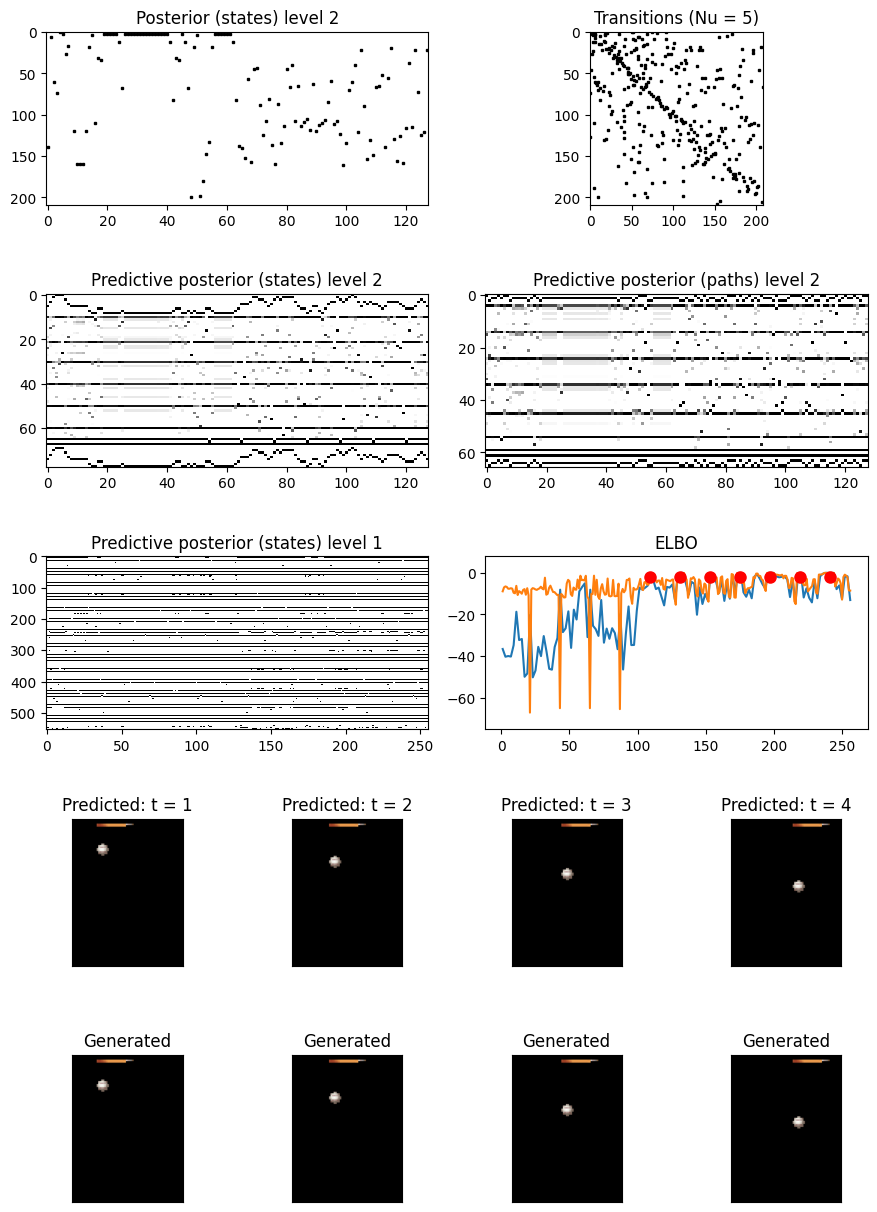

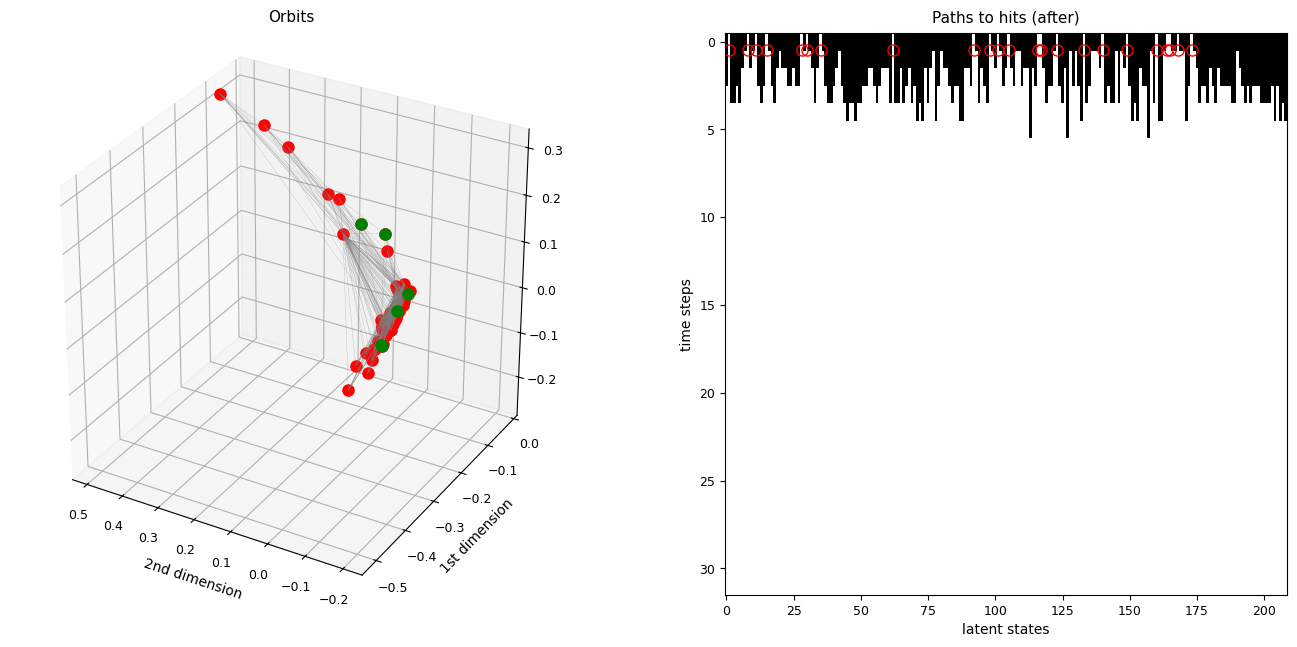

In [12]:
Nm = len(MDP)
plot_ctx = {"RGB": RGB, "GDP": GDP, "Nm": Nm}
RDP, _j = spm_RDP_sort(MDP)
RDP = spm_RDP_MI(RDP)
RDP = spm_set_goals(RDP, [2, 3], [float(C), -float(C)])
RDP = spm_set_costs(RDP, [2, 3], [float(C), -float(C)])
RDP = spm_mdp2rdp(RDP, 0, 1.0 / float(NS))
RDP["T"] = 128.0

PDP = spm_MDP_VB_XXX(RDP, {})

png_rgb = out_dir / "AtariIII_colab1_dem_with_compression_rgb.png"
dem_atariiii_plot_with_compression_rgb(PDP, plot_ctx, save_png=True, png_path=png_rgb)
plt.show()
png_orb = out_dir / "AtariIII_colab1_dem_orbits_after.png"
dem_atariiii_plot_orbits_after(PDP, plot_ctx, save_png=True, png_path=png_orb, eig=None, svd=None)
plt.show()

### Cell 11 — Parameter count and wrap-up

#### Counting Dirichlet parameters

`np_count = count_mdp_parameters(MDP)` tallies the **nonzero entries** of the hierarchical Dirichlet tensors in **`MDP`** (likelihood cells **`a`** and transition cells **`b`** across levels)—a simple size measure of the learned Atari RGM after structure learning, basin shaping, and the Cell 8 continued-learning loop.

#### Wrap-up: Atari III as an RGM pipeline

This notebook walked one end-to-end renormalising-generative-model story:

1. **Process** — multi-stream Pong (`GDP`, `RGB`) with pixels, reward, constraint, and control.
2. **Data** — long random play (`PDP` from `spm_MDP_generate`).
3. **Fast structure learning** — renormalisation $\mathcal{R}_n$ into hierarchy **`MDP`**, then rewarded-window merges.
4. **Basins** — deep dynamics shaped toward goals under costs (`spm_RDP_basin`).
5. **Sort** — NESS-style prune/order of deep states; orbits / paths to hits.
6. **Fantasy play** — recursive generation without the process (`spm_mdp2rdp` + `spm_MDP_VB_XXX`).
7. **Active inference** — process installed; play, merge self-generated outcomes, re-basin; metrics in **`F`**.
8. **Before / after compression** — intentional play and deep geometry with and without **`spm_RDP_MI`**.
9. **Size** — remaining nonzero Dirichlet parameters in **`MDP`**.

Together, these steps show how RGMs turn high-dimensional multi-stream play into a hierarchical model for inference, planning, continued learning, and efficient deep policies.

In [13]:
np_count = count_mdp_parameters(MDP)
print("number of parameters", flush=True)
print(np_count, flush=True)


number of parameters
8815
